Dataset shape: (1797, 64)
Target shape: (1797,)

First five digit labels:
[0 1 2 3 4]


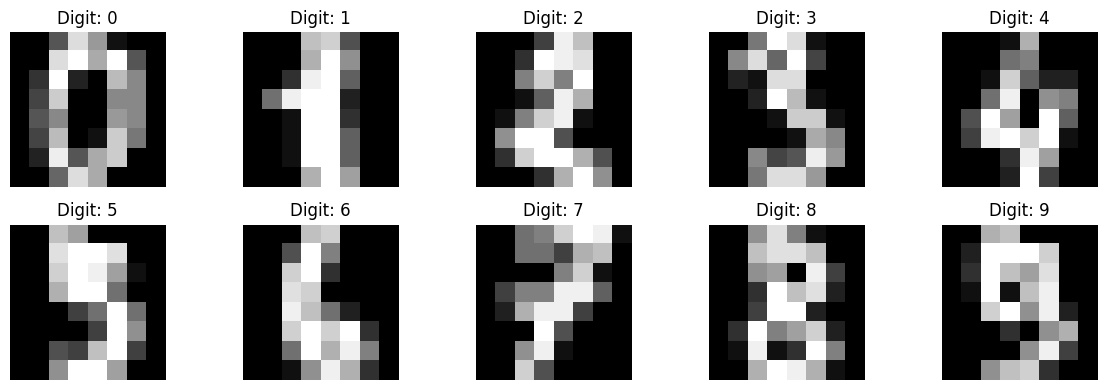


Training data shape: (1437, 64)
Testing data shape: (360, 64)

SVM model trained successfully!

Predicted digits:
[5 2 8 1 7 2 6 2 6 5 0 5 9 3 4 4 2 4 9 9]

Actual digits:
[5 2 8 1 7 2 6 2 6 5 0 5 9 3 4 4 2 4 9 9]

SVM Model Accuracy:
98.06 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      0.97      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       0.97      1.00      0.99        37
           6       0.97      1.00      0.99        36
           7       0.95      0.97      0.96        36
           8       1.00      0.94      0.97        35
           9       1.00      0.94      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98     

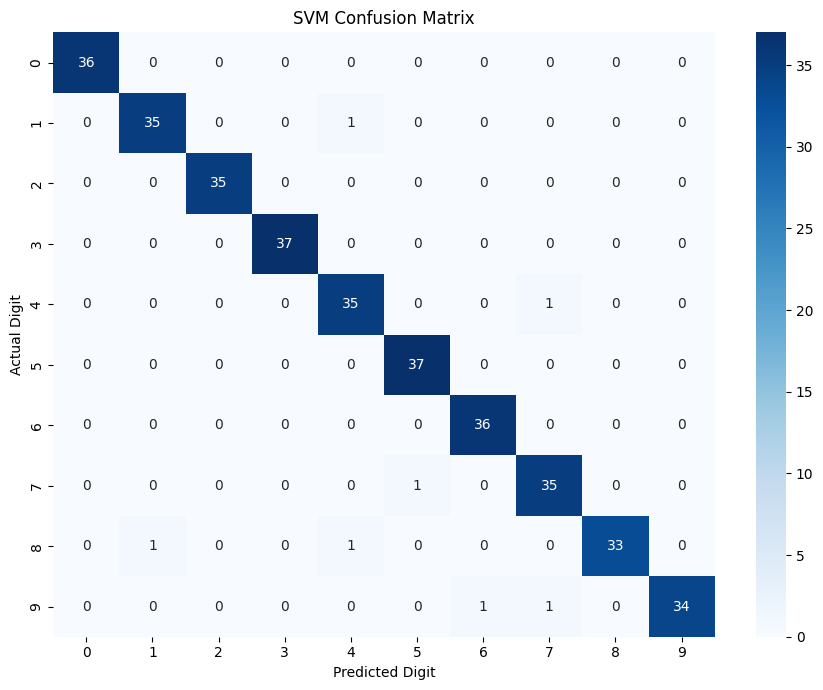

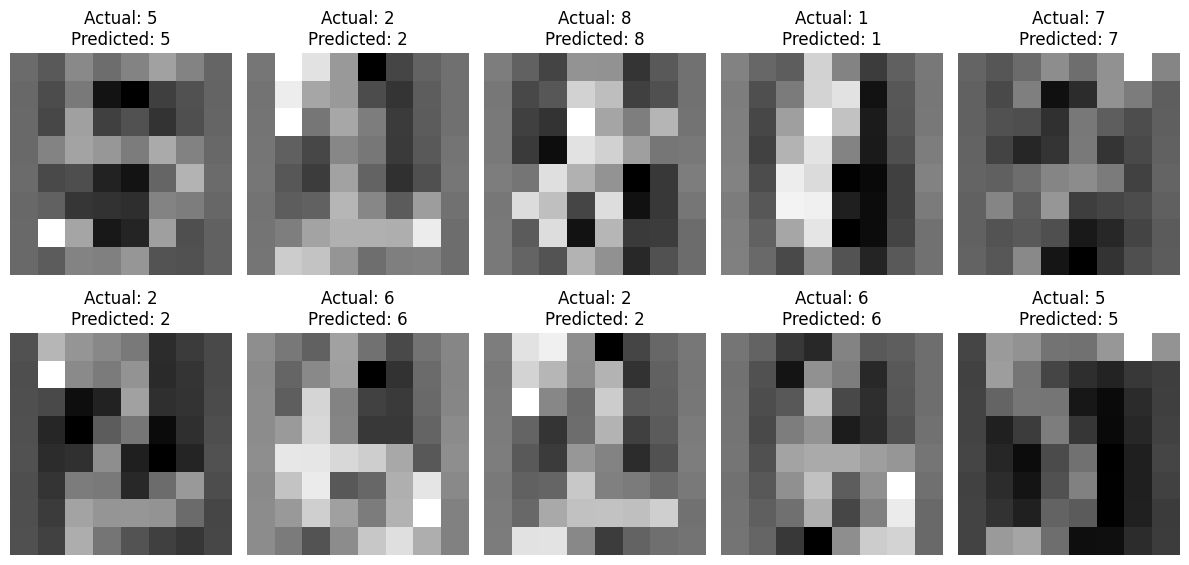

In [1]:

# ==========================================================
# EXPERIMENT NO. 3: CLASSIFICATION ANALYSIS USING SVM
# Aim: Classify handwritten digits from 0 to 9 using SVM.
# ==========================================================


# STEP 1: Import required libraries

import numpy as np
import matplotlib.pyplot as plt

# Import handwritten digits dataset
from sklearn.datasets import load_digits

# Import functions for splitting and scaling data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Import SVM classifier
from sklearn.svm import SVC

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import seaborn as sns


# STEP 2: Load the handwritten digits dataset

# Load the built-in digits dataset from Scikit-learn
digits = load_digits()

# X contains image pixel values
X = digits.data

# y contains the actual digit labels (0 to 9)
y = digits.target

# Display dataset shape
print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

# Display the first five target labels
print("\nFirst five digit labels:")
print(y[:5])


# STEP 3: Visualize sample handwritten digits

# Display the first 10 handwritten digit images
plt.figure(figsize=(12, 4))

for i in range(10):

    # Create a subplot for each digit
    plt.subplot(2, 5, i + 1)

    # Display the image
    plt.imshow(digits.images[i], cmap="gray")

    # Display the actual digit label
    plt.title("Digit: " + str(y[i]))

    # Hide axis values
    plt.axis("off")

plt.tight_layout()
plt.show()


# STEP 4: Split dataset into training and testing data

# 80% data is used for training
# 20% data is used for testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


# STEP 5: Standardize the data

# StandardScaler brings all features to a common scale.
# This helps SVM perform better.

scaler = StandardScaler()

# Learn scaling values from training data and transform it
X_train = scaler.fit_transform(X_train)

# Apply the same scaling to testing data
X_test = scaler.transform(X_test)


# STEP 6: Create the SVM model

# SVC stands for Support Vector Classifier.
# RBF kernel can identify nonlinear patterns.
# C controls the regularization strength.
# gamma controls how far the influence of each point reaches.

model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)


# STEP 7: Train the SVM model

# Train the model using training data
model.fit(X_train, y_train)

print("\nSVM model trained successfully!")


# STEP 8: Predict handwritten digits

# Predict labels for testing images
y_pred = model.predict(X_test)

print("\nPredicted digits:")
print(y_pred[:20])

print("\nActual digits:")
print(y_test[:20])


# STEP 9: Calculate accuracy

# Compare predicted labels with actual labels
accuracy = accuracy_score(y_test, y_pred)

print("\nSVM Model Accuracy:")
print(round(accuracy * 100, 2), "%")


# STEP 10: Display classification report

# Shows precision, recall, F1-score and support
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# STEP 11: Create confusion matrix

# Compare actual and predicted digit classes
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix as a heatmap
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.tight_layout()
plt.show()


# STEP 12: Display predicted images

# Show some test images with actual and predicted labels
plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    # Reshape the 64 pixel values into an 8x8 image
    image = X_test[i].reshape(8, 8)

    # Display image
    plt.imshow(image, cmap="gray")

    # Display actual and predicted values
    plt.title(
        "Actual: " + str(y_test[i]) +
        "\nPredicted: " + str(y_pred[i])
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


# ==========================================================
# END OF EXPERIMENT NO. 3
# ==========================================================
